# Análise exploratória da precipitação em Belém (PA)

**Fonte:** dados históricos do INMET  
**Período de interesse:** 2003–2026

Este notebook consome os arquivos produzidos pela camada **Gold** do pipeline de medalhão. Ele não executa novamente a ingestão ou o tratamento.

> Antes de interpretar os resultados, confira a cobertura temporal, a estação meteorológica e a quantidade de registros válidos por ano. O ano de 2026 pode estar incompleto.

## 1. Importar bibliotecas e configurar caminhos

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Salve este notebook dentro da pasta notebooks/
PROJECT_ROOT = Path.cwd().parent
GOLD_DIR = PROJECT_ROOT / "data" / "gold"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "notebook"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Pasta Gold:", GOLD_DIR)
print("Pasta de gráficos:", OUTPUT_DIR)

Pasta Gold: c:\Users\davic\VS code\Projetos profissionais\hora_chuva_belem\data\gold
Pasta de gráficos: c:\Users\davic\VS code\Projetos profissionais\hora_chuva_belem\outputs\notebook


## 2. Carregar as tabelas Gold

In [2]:
arquivo_hora = GOLD_DIR / "chuva_por_hora.csv"
arquivo_mes = GOLD_DIR / "chuva_por_mes.csv"
arquivo_ano = GOLD_DIR / "chuva_por_ano.csv"

chuva_hora = pd.read_csv(arquivo_hora)
chuva_mes = pd.read_csv(arquivo_mes)
chuva_ano = pd.read_csv(arquivo_ano)

display(chuva_hora.head())
display(chuva_mes.head())
display(chuva_ano.head())

,hora,quantidade_registros_com_chuva,precipitacao_acumulada_mm,precipitacao_media_mm
0,0,555,833.6,1.501982
1,1,493,831.4,1.686410
2,2,471,787.8,1.672611
3,3,459,635.0,1.383442
4,4,409,551.2,1.347677


,mes,precipitacao_acumulada_mm,precipitacao_media_por_registro_mm,registros_validos
0,1,9011.4,0.527878,17071
1,2,10297.6,0.648300,15884
2,3,11886.2,0.705580,16846
3,4,9635.0,0.592558,16260
4,5,7659.2,0.502572,15240


,ano,precipitacao_acumulada_mm,precipitacao_media_por_registro_mm,registros_validos
0,2003,2804.2,0.450764,6221
1,2004,2768.6,0.554274,4995
2,2005,2674.4,0.408617,6545
3,2006,1982.4,0.348830,5683
4,2007,2328.0,0.392978,5924


## 3. Verificar qualidade e cobertura dos dados

In [3]:
print("Formato da tabela anual:", chuva_ano.shape)
print("\\nValores ausentes por coluna:")
display(chuva_ano.isna().sum().to_frame("valores_ausentes"))
display(chuva_ano.describe(include="all"))

Formato da tabela anual: (24, 4)
\nValores ausentes por coluna:


,valores_ausentes
ano,0
precipitacao_acumulada_mm,0
precipitacao_media_por_registro_mm,0
registros_validos,0


,ano,precipitacao_acumulada_mm,precipitacao_media_por_registro_mm,registros_validos
count,24.000000,24.000000,24.000000,24.000000
mean,2014.500000,3130.058333,0.399609,7891.625000
std,7.071068,601.414679,0.066254,1165.600118
min,2003.000000,1982.400000,0.309918,4995.000000
25%,2008.750000,2765.350000,0.355999,7221.250000
50%,2014.500000,3065.700000,0.381889,8471.500000
75%,2020.250000,3266.150000,0.449891,8688.750000
max,2026.000000,4301.400000,0.554274,8784.000000


In [4]:
# Diagnóstico de cobertura anual usando a Silver
arquivo_silver = PROJECT_ROOT / "data" / "silver" / "precipitacao_tratada.csv"

if arquivo_silver.exists():
    silver = pd.read_csv(arquivo_silver, parse_dates=["data_hora_local"])
    silver["ano"] = silver["data_hora_local"].dt.year

    cobertura_anual = (
        silver.groupby("ano")
        .agg(
            total_registros=("precipitacao_mm", "size"),
            registros_validos=("precipitacao_mm", "count"),
            primeiro_registro=("data_hora_local", "min"),
            ultimo_registro=("data_hora_local", "max"),
        )
        .reset_index()
    )
    display(cobertura_anual)
else:
    print("Silver não encontrada:", arquivo_silver)

,ano,total_registros,registros_validos,primeiro_registro,ultimo_registro
0,2003,8307,6221,2003-01-19 21:00:00-03:00,2003-12-31 23:00:00-03:00
1,2004,8784,4995,2004-01-01 00:00:00-03:00,2004-12-31 23:00:00-03:00
2,2005,8760,6545,2005-01-01 00:00:00-03:00,2005-12-31 23:00:00-03:00
3,2006,8760,5683,2006-01-01 00:00:00-03:00,2006-12-31 23:00:00-03:00
4,2007,8760,5924,2007-01-01 00:00:00-03:00,2007-12-31 23:00:00-03:00
5,2008,8784,7111,2008-01-01 00:00:00-03:00,2008-12-31 23:00:00-03:00
6,2009,8760,8267,2009-01-01 00:00:00-03:00,2009-12-31 23:00:00-03:00
7,2010,8760,8747,2010-01-01 00:00:00-03:00,2010-12-31 23:00:00-03:00
8,2011,8760,8674,2011-01-01 00:00:00-03:00,2011-12-31 23:00:00-03:00
9,2012,8784,8565,2012-01-01 00:00:00-03:00,2012-12-31 23:00:00-03:00


## 4. Precipitação acumulada por ano

O acumulado anual é a soma dos registros válidos disponíveis. Em anos com lacunas, esse total pode subestimar a precipitação real; avalie a cobertura antes de comparar anos.

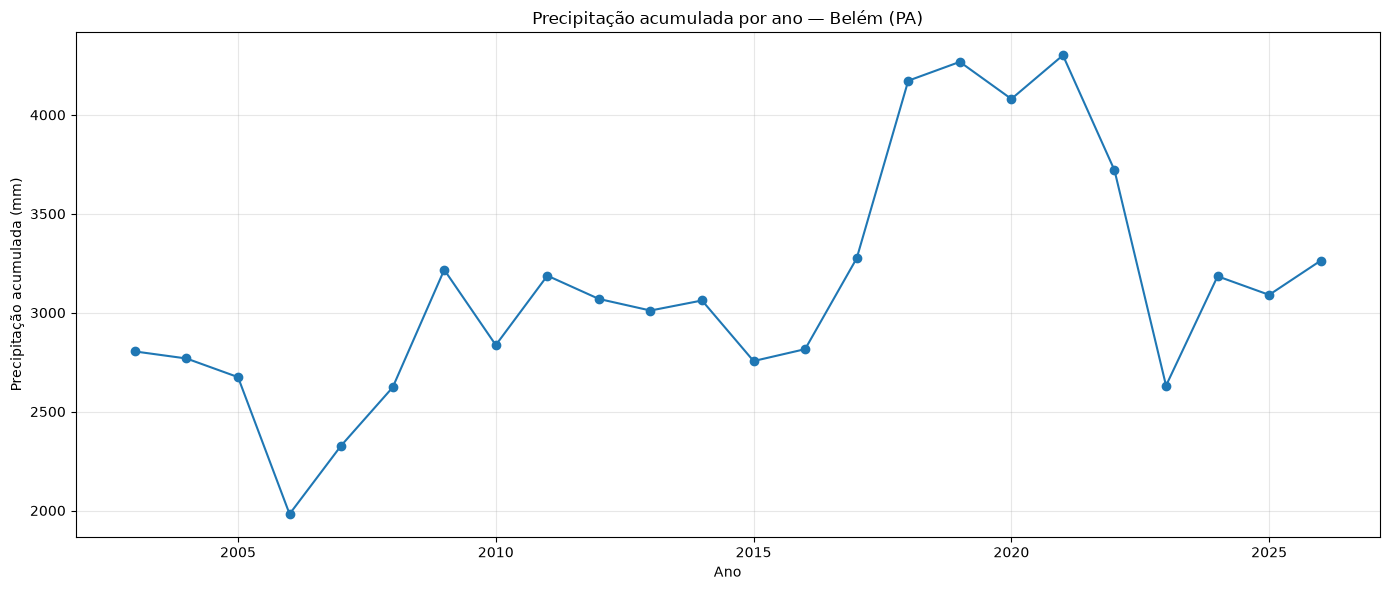

In [5]:
plt.figure(figsize=(14, 6))
plt.plot(
    chuva_ano["ano"],
    chuva_ano["precipitacao_acumulada_mm"],
    marker="o"
)
plt.title("Precipitação acumulada por ano — Belém (PA)")
plt.xlabel("Ano")
plt.ylabel("Precipitação acumulada (mm)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precipitacao_por_ano.png", dpi=150)
plt.show()

## 5. Frequência de registros com chuva por hora local

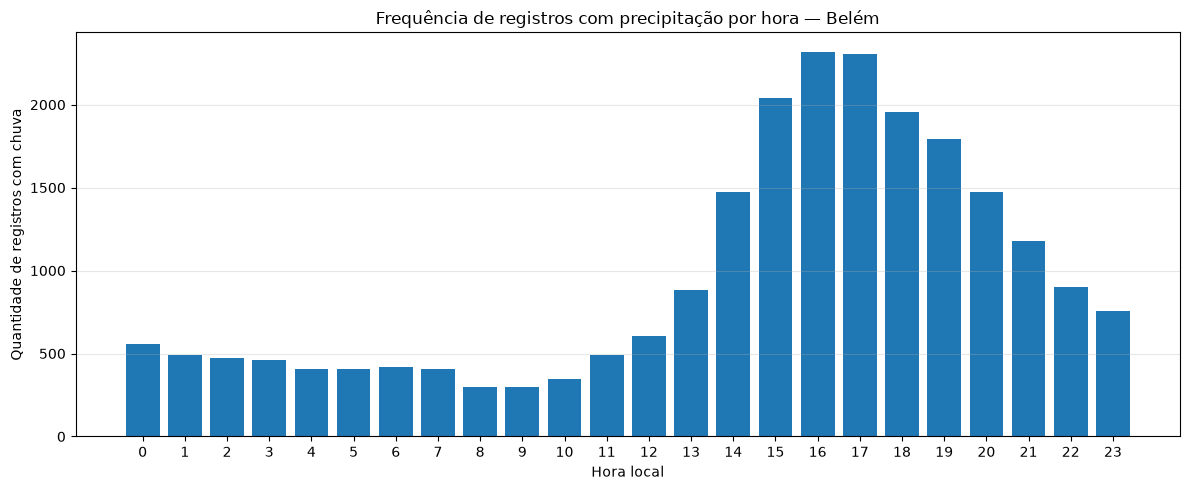

In [6]:
plt.figure(figsize=(12, 5))
plt.bar(
    chuva_hora["hora"],
    chuva_hora["quantidade_registros_com_chuva"]
)
plt.title("Frequência de registros com precipitação por hora — Belém")
plt.xlabel("Hora local")
plt.ylabel("Quantidade de registros com chuva")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "frequencia_chuva_por_hora.png", dpi=150)
plt.show()

## 6. Precipitação acumulada por mês do calendário

A tabela Gold mensal agrega os registros de todos os anos. Para estudar sazonalidade, considere também calcular a média mensal por ano ou a média de cada mês ao longo dos anos completos.

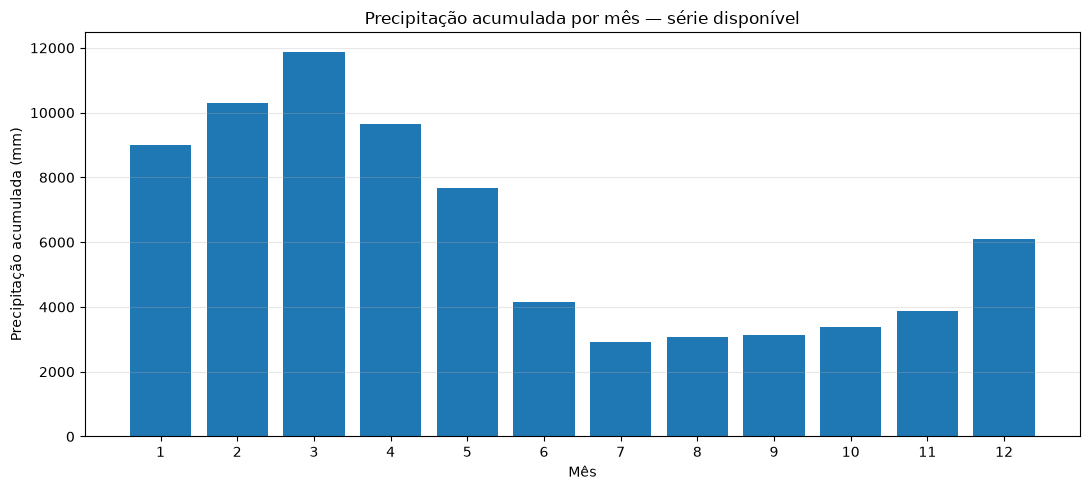

In [7]:
plt.figure(figsize=(11, 5))
plt.bar(
    chuva_mes["mes"],
    chuva_mes["precipitacao_acumulada_mm"]
)
plt.title("Precipitação acumulada por mês — série disponível")
plt.xlabel("Mês")
plt.ylabel("Precipitação acumulada (mm)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precipitacao_por_mes.png", dpi=150)
plt.show()

## 7. Mês com maior precipitação em cada ano

In [8]:
# Carregar a Silver
silver = pd.read_csv(
    "../data/silver/precipitacao_tratada.csv",
    parse_dates=["data_hora_local"]
)

silver["ano"] = silver["data_hora_local"].dt.year
silver["mes"] = silver["data_hora_local"].dt.month

# Acumulado mensal por ano
precipitacao_mensal = (
    silver.dropna(subset=["precipitacao_mm"])
    .groupby(["ano", "mes"], as_index=False)["precipitacao_mm"]
    .sum()
    .rename(columns={
        "precipitacao_mm": "precipitacao_mensal_mm"
    })
)

# Mês de maior precipitação em cada ano
indice_maximo = precipitacao_mensal.groupby("ano")[
    "precipitacao_mensal_mm"
].idxmax()

mes_maior_precipitacao = (
    precipitacao_mensal.loc[indice_maximo]
    .sort_values("ano")
    .reset_index(drop=True)
)

display(mes_maior_precipitacao)

,ano,mes,precipitacao_mensal_mm
0,2003,3,601.6
1,2004,2,665.2
2,2005,12,495.4
3,2006,12,456.4
4,2007,4,491.2
5,2008,1,488.4
6,2009,3,613.2
7,2010,4,452.4
8,2011,4,464.2
9,2012,3,552.4


## 8.   Dia com maior precipitação em cada ano

In [9]:
silver["data"] = silver["data_hora_local"].dt.date

precipitacao_diaria = (
    silver.dropna(subset=["precipitacao_mm"])
    .groupby(["ano", "data"], as_index=False)["precipitacao_mm"]
    .sum()
    .rename(columns={
        "precipitacao_mm": "precipitacao_diaria_mm"
    })
)

# Dia de maior precipitação em cada ano
indice_maximo = precipitacao_diaria.groupby("ano")[
    "precipitacao_diaria_mm"
].idxmax()

dia_maior_precipitacao = (
    precipitacao_diaria.loc[indice_maximo]
    .sort_values("ano")
    .reset_index(drop=True)
)

display(dia_maior_precipitacao)

,ano,data,precipitacao_diaria_mm
0,2003,2003-02-16,69.6
1,2004,2004-04-23,90.8
2,2005,2005-01-21,63.4
3,2006,2006-03-01,72.4
4,2007,2007-01-27,75.4
5,2008,2008-03-31,90.2
6,2009,2009-02-12,73.6
7,2010,2010-05-06,79.4
8,2011,2011-02-18,125.0
9,2012,2012-09-27,75.0


## 9. Perguntas para orientar a interpretação

1. Quais horários apresentam maior frequência de precipitação registrada?
2. Quais meses concentram maior precipitação acumulada?
3. Quais anos possuem cobertura incompleta ou valores suspeitos?
4. Há diferenças relevantes entre períodos da série?
5. Os resultados mudam quando consideramos apenas anos com boa cobertura?

**Nota metodológica:** precipitação horária maior que zero indica chuva registrada naquele intervalo; não identifica necessariamente o instante exato em que o evento começou.